# Summary

The important points to know from this week are:

- The assumptions under pinning discrete time Geometric Brownian motion, the difference equation used to simulate the log of the stock price and the importance of the terms appearing in it.
- Simulating discrete time Geometric Brownian motion in Python and using fan diagrams to visualise how the distribution of the stock price changes with time.
- The \(von Neumann Morgernstern utility theorem and how we can use utility functions to capture risk and preference over outcomes.
- Showing the optimal consumption and investment proportions for the infinite horizon Merton problem are independent of time, wealth and the stock price.



In [1]:
import numpy as np
import matplotlib .pyplot as plt

rng = np.random.default_rng(2026)

def simulate_gbm(S0, mu, sigma, T, n_steps):
    dt = T / n_steps
    Z = np.zeros(n_steps+1)
    Z[0] = np.log(S0)
    epsilon = rng.standard_normal(n_steps)

    for i in range(n_steps):
        Z[i+1] = Z[i] + (mu - 0.5* sigma**2) *dt + sigma * np.sqrt(dt) * epsilon[i]
    
    return np.exp(Z)

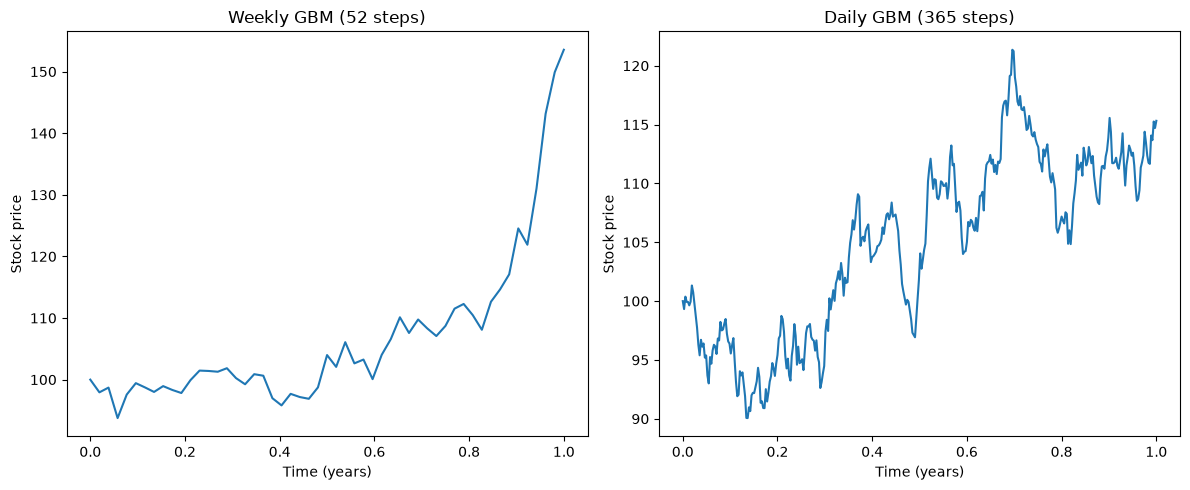

In [41]:
S0, mu, sigma, T = 100, 0.08, 0.2, 1

n_steps = 52
S_week = simulate_gbm(S0, mu, sigma, T, n_steps)
times_week = np.linspace(0, T, n_steps + 1)

n_steps = 365
S_day = simulate_gbm(S0, mu, sigma, T, n_steps)
times_day = np.linspace(0, T, n_steps + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(times_week, S_week)
axes[1].plot(times_day, S_day)

for ax in axes:
    ax.set(xlabel="Time (years)", ylabel="Stock price")

axes[0].set_title("Weekly GBM (52 steps)")
axes[1].set_title("Daily GBM (365 steps)")

fig.tight_layout()

In [23]:
def simulate_gbm_paths(S0, mu, sigma, T, n_steps, n_paths):
    dt = T / n_steps
    times = np.linspace(0, T, n_steps+1)
    Z = np.zeros((n_paths, n_steps+1))
    Z[:, 0] = np.log(S0)
    epsilon = rng.standard_normal((n_paths, n_steps))

    for i in range(n_steps):
        Z[:, i+1] = Z[:, i] + (mu - 0.5* sigma**2) *dt + sigma * np.sqrt(dt) * epsilon[:, i]
    
    return np.exp(Z),times

S, times = simulate_gbm_paths(S0,mu,sigma,T,365,2000)

print(S.shape)

(2000, 366)


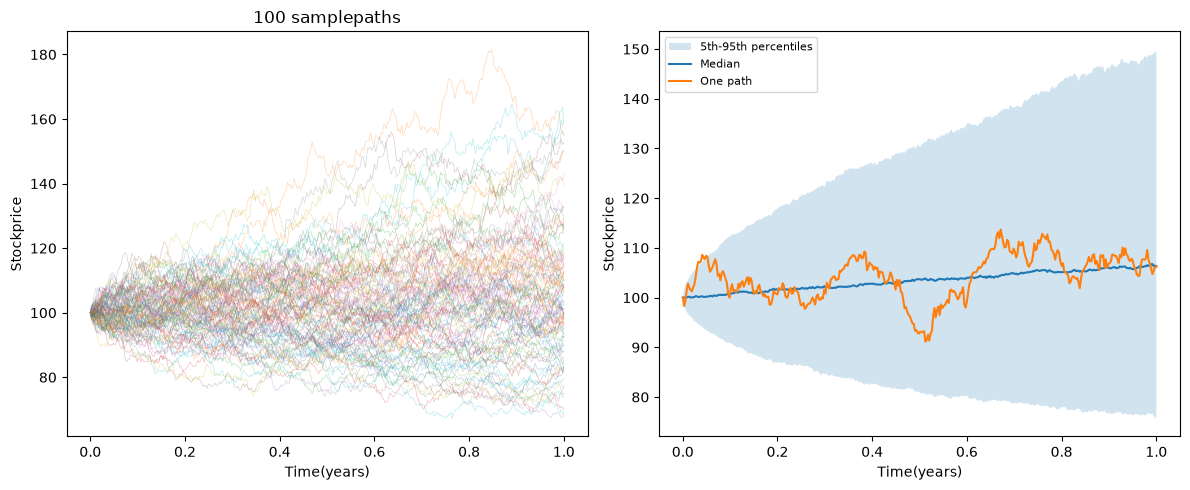

In [30]:
lower,median,upper=np.percentile(S,[5,50,95],axis=0) 
fig,axes= plt.subplots(1,2,figsize=(12,5)) 

axes[0].plot(times,S[:100].T,linewidth=0.5,alpha=0.3) 
axes[0].set_title("100 samplepaths") 

axes[1].fill_between(times,lower,upper,alpha=0.2, label="5th-95th percentiles") 
axes[1].plot(times,median,label="Median") 
axes[1].plot(times,S[0],label="One path") 
axes[1].legend(fontsize=8) 

for ax in axes: 
    ax.set(xlabel="Time(years)",ylabel="Stockprice") 

fig.tight_layout()